In [1]:
dia = '2024-04-13'

### Instalando o PyCaret

In [2]:
!pip install pycaret

### Importando as Bibliotecas e Funções

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from pycaret.classification import *

import warnings
warnings.filterwarnings('ignore')

def drop_reset_index(df):
    df = df.dropna()
    df = df.reset_index(drop=True)
    df.index += 1
    return df

def read_base():
    base = pd.read_csv("https://github.com/futpythontrader/YouTube/raw/main/Bases_de_Dados/FlashScore/Base_de_Dados_FlashScore_v2.csv")
    base["Date"] = pd.to_datetime(base["Date"])
    base = base[['League','Round','Date','Home','Away','Goals_H','Goals_A','Odd_H','Odd_D','Odd_A','Odd_Over25','Odd_Under25','Odd_BTTS_Yes','Odd_BTTS_No','Goals_Minutes_Home','Goals_Minutes_Away']]
    base = drop_reset_index(base)
    return base

def read_jogos(dia):
    jogos_do_dia = pd.read_csv(f'https://github.com/futpythontrader/YouTube/raw/main/Jogos_do_Dia/FlashScore/Jogos_do_Dia_FlashScore_{dia}.csv')
    jogos_do_dia = jogos_do_dia[['League','Round','Date','Time','Home','Away','Odd_H','Odd_D','Odd_A','Odd_Over25','Odd_Under25','Odd_BTTS_Yes','Odd_BTTS_No']]
    jogos_do_dia = drop_reset_index(jogos_do_dia)
    return jogos_do_dia

### Importando os Jogos do Dia e a Base de Dados

In [4]:
Jogos_do_Dia = read_jogos(dia)
base_orig = read_base()

In [5]:
leagues_full = Jogos_do_Dia.sort_values(by='League')
leagues_full = leagues_full['League'].unique()
leagues_full

array(['ARGENTINA - COPA DE LA LIGA PROFESIONAL',
       'ARMENIA - PREMIER LEAGUE', 'AUSTRALIA - A-LEAGUE',
       'AUSTRIA - 2. LIGA', 'AUSTRIA - BUNDESLIGA',
       'BELGIUM - CHALLENGER PRO LEAGUE', 'BELGIUM - JUPILER PRO LEAGUE',
       'BRAZIL - SERIE A', 'BULGARIA - PARVA LIGA',
       'CHILE - PRIMERA DIVISION', 'CHINA - SUPER LEAGUE',
       'COLOMBIA - PRIMERA A', 'CROATIA - HNL',
       'CYPRUS - CYTA CHAMPIONSHIP', 'CZECH REPUBLIC - FORTUNA:LIGA',
       'DENMARK - 1ST DIVISION', 'ECUADOR - LIGA PRO',
       'ENGLAND - CHAMPIONSHIP', 'ENGLAND - LEAGUE ONE',
       'ENGLAND - LEAGUE TWO', 'ENGLAND - PREMIER LEAGUE',
       'ESTONIA - MEISTRILIIGA', 'FINLAND - VEIKKAUSLIIGA',
       'FINLAND - YKKONEN', 'FRANCE - LIGUE 1', 'FRANCE - LIGUE 2',
       'GERMANY - 2. BUNDESLIGA', 'GERMANY - 3. LIGA',
       'GERMANY - BUNDESLIGA', 'GREECE - SUPER LEAGUE',
       'HUNGARY - OTP BANK LIGA', 'ICELAND - BESTA DEILD KARLA',
       "ISRAEL - LIGAT HA'AL", 'ITALY - SERIE A', 'ITALY - SE

In [6]:
league = ['SPAIN - LALIGA']
Jogos_do_Dia = Jogos_do_Dia[Jogos_do_Dia['League'].isin(league) == True]
Jogos_do_Dia = drop_reset_index(Jogos_do_Dia)
Jogos_do_Dia

,League,Round,Date,Time,Home,Away,Odd_H,Odd_D,Odd_A,Odd_Over25,Odd_Under25,Odd_BTTS_Yes,Odd_BTTS_No
1,SPAIN - LALIGA,ROUND 31,13/04/2024,09:00,Atl. Madrid,Girona,1.91,3.6,3.80,1.62,2.25,1.57,2.25
2,SPAIN - LALIGA,ROUND 31,13/04/2024,11:15,Rayo Vallecano,Getafe,2.20,3.0,3.70,2.60,1.48,2.10,1.67
3,SPAIN - LALIGA,ROUND 31,13/04/2024,13:30,Mallorca,Real Madrid,5.00,3.6,1.75,2.08,1.73,1.95,1.80
4,SPAIN - LALIGA,ROUND 31,13/04/2024,16:00,Cadiz CF,Barcelona,4.33,3.6,1.83,2.01,1.89,1.80,1.95


In [7]:
base = base_orig[base_orig['League'].isin(league) == True]
base = base.sort_values('Date')
flt = base.Date < str(dia)
base = base[flt]
base = drop_reset_index(base)
base

,League,Round,Date,Home,Away,Goals_H,Goals_A,Odd_H,Odd_D,Odd_A,Odd_Over25,Odd_Under25,Odd_BTTS_Yes,Odd_BTTS_No,Goals_Minutes_Home,Goals_Minutes_Away
1,SPAIN - LALIGA,ROUND 1,2021-08-13,Valencia,Getafe,1,0,2.37,3.00,3.30,2.75,1.44,2.20,1.61,[11],[]
2,SPAIN - LALIGA,ROUND 1,2021-08-14,Cadiz CF,Levante,1,1,3.30,3.25,2.20,2.30,1.61,1.95,1.80,[90],[39]
3,SPAIN - LALIGA,ROUND 1,2021-08-14,Mallorca,Betis,1,1,2.45,3.10,3.10,2.37,1.57,2.00,1.75,[25],[59]
4,SPAIN - LALIGA,ROUND 1,2021-08-14,Alaves,Real Madrid,1,4,6.00,4.20,1.57,1.90,1.90,1.90,1.90,[65],"[48, 56, 62, 90]"
5,SPAIN - LALIGA,ROUND 1,2021-08-14,Osasuna,Espanyol,0,0,2.55,3.20,2.87,2.37,1.57,2.00,1.75,[],[]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1057,SPAIN - LALIGA,ROUND 30,2024-03-31,Alaves,Real Sociedad,0,1,4.00,3.00,2.15,2.70,1.44,2.20,1.62,[],[59]
1058,SPAIN - LALIGA,ROUND 30,2024-03-31,Real Madrid,Ath Bilbao,2,0,1.57,4.33,5.75,1.75,2.05,1.80,1.95,"[8, 73]",[]
1059,SPAIN - LALIGA,ROUND 30,2024-04-01,Villarreal,Atl. Madrid,1,2,3.40,3.60,2.05,1.73,2.08,1.62,2.20,[50],"[9, 87]"
1060,SPAIN - LALIGA,ROUND 26,2024-04-04,Granada CF,Valencia,0,1,3.00,3.00,2.55,2.20,1.65,1.80,1.95,[],[77]


In [8]:
df = base.copy()

# Probabilidades
df['p_H'] = 1 / df['Odd_H']
df['p_D'] = 1 / df['Odd_D']
df['p_A'] = 1 / df['Odd_A']
df['p_Over'] = 1 / df['Odd_Over25']
df['p_Under'] = 1 / df['Odd_Under25']
df['p_BTTS_Y'] = 1 / df['Odd_BTTS_Yes']
df['p_BTTS_N'] = 1 / df['Odd_BTTS_No']

# CV das Probabilidades
desvio_padrao = df[['p_H','p_D','p_A']].std(axis=1)
media = df[['p_H','p_D','p_A']].mean(axis=1)
cv_odds = desvio_padrao / media
df['CV_Odds_MO'] = cv_odds

n_per = 5

# Média de Pontos
df['Ptos_H'] = np.where(df['Goals_H'] > df['Goals_A'], 3, np.where(df['Goals_H'] == df['Goals_A'], 1, 0))
df['Ptos_A'] = np.where(df['Goals_A'] > df['Goals_H'], 3, np.where(df['Goals_A'] == df['Goals_H'], 1, 0))
df['Media_Ptos_H'] = df.groupby('Home')['Ptos_H'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_Ptos_A'] = df.groupby('Away')['Ptos_A'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_Ptos_H'] = df.groupby('Home')['Media_Ptos_H'].shift(1)
df['Media_Ptos_A'] = df.groupby('Away')['Media_Ptos_A'].shift(1)
df['DesvPad_Ptos_H'] = df.groupby('Home')['Ptos_H'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_Ptos_A'] = df.groupby('Away')['Ptos_A'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_Ptos_H'] = df.groupby('Home')['DesvPad_Ptos_H'].shift(1)
df['DesvPad_Ptos_A'] = df.groupby('Away')['DesvPad_Ptos_A'].shift(1)
df['CV_Ptos_H'] = df['DesvPad_Ptos_H'] / df['Media_Ptos_H']
df['CV_Ptos_A'] = df['DesvPad_Ptos_A'] / df['Media_Ptos_A']

# Média de Gols Marcados
df['Media_GM_H'] = df.groupby('Home')['Goals_H'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GM_A'] = df.groupby('Away')['Goals_A'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GM_H'] = df.groupby('Home')['Media_GM_H'].shift(1)
df['Media_GM_A'] = df.groupby('Away')['Media_GM_A'].shift(1)
df['DesvPad_GM_H'] = df.groupby('Home')['Goals_H'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GM_A'] = df.groupby('Away')['Goals_A'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GM_H'] = df.groupby('Home')['DesvPad_GM_H'].shift(1)
df['DesvPad_GM_A'] = df.groupby('Away')['DesvPad_GM_A'].shift(1)
df['CV_GM_H'] = df['DesvPad_GM_H'] / df['Media_GM_H']
df['CV_GM_A'] = df['DesvPad_GM_A'] / df['Media_GM_A']

# Média de Gols Sofridos
df['Media_GS_H'] = df.groupby('Home')['Goals_A'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GS_A'] = df.groupby('Away')['Goals_H'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_GS_H'] = df.groupby('Home')['Media_GS_H'].shift(1)
df['Media_GS_A'] = df.groupby('Away')['Media_GS_A'].shift(1)
df['DesvPad_GS_H'] = df.groupby('Home')['Goals_A'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GS_A'] = df.groupby('Away')['Goals_H'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_GS_H'] = df.groupby('Home')['DesvPad_GS_H'].shift(1)
df['DesvPad_GS_A'] = df.groupby('Away')['DesvPad_GS_A'].shift(1)
df['CV_GS_H'] = df['DesvPad_GS_H'] / df['Media_GS_H']
df['CV_GS_A'] = df['DesvPad_GS_A'] / df['Media_GS_A']

# Média de Saldo de Gols
df['SG_H'] = df['Goals_H'] - df['Goals_A']
df['SG_A'] = df['Goals_A'] - df['Goals_H']
df['Media_SG_H'] = df.groupby('Home')['SG_H'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_A'] = df.groupby('Away')['SG_A'].rolling(window=n_per,min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_H'] = df.groupby('Home')['Media_SG_H'].shift(1)
df['Media_SG_A'] = df.groupby('Away')['Media_SG_A'].shift(1)
df['DesvPad_SG_H'] = df.groupby('Home')['SG_H'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_SG_A'] = df.groupby('Away')['SG_A'].rolling(window=n_per,min_periods=n_per).std().reset_index(0,drop=True)
df['DesvPad_SG_H'] = df.groupby('Home')['DesvPad_SG_H'].shift(1)
df['DesvPad_SG_A'] = df.groupby('Away')['DesvPad_SG_A'].shift(1)
df['CV_SG_H'] = df['DesvPad_SG_H'] / df['Media_SG_H']
df['CV_SG_A'] = df['DesvPad_SG_A'] / df['Media_SG_A']

# Média de Saldo de Gols Ponderado pela Probabilidade do Time
df['SG_H_01'] = (df['Goals_H'] - df['Goals_A']) / df['p_H']
df['SG_A_01'] = (df['Goals_A'] - df['Goals_H']) / df['p_A']
df['Media_SG_H_01'] = df.groupby('Home')['SG_H_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_A_01'] = df.groupby('Away')['SG_A_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_H_01'] = df.groupby('Home')['Media_SG_H_01'].shift(1)
df['Media_SG_A_01'] = df.groupby('Away')['Media_SG_A_01'].shift(1)
df['DesvPad_SG_H_01'] = df.groupby('Home')['SG_H_01'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_SG_A_01'] = df.groupby('Away')['SG_A_01'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_SG_H_01'] = df.groupby('Home')['DesvPad_SG_H_01'].shift(1)
df['DesvPad_SG_A_01'] = df.groupby('Away')['DesvPad_SG_A_01'].shift(1)
df['CV_SG_H_01'] = df['DesvPad_SG_H_01'] / df['Media_SG_H_01']
df['CV_SG_A_01'] = df['DesvPad_SG_A_01'] / df['Media_SG_A_01']

# Média de Saldo de Gols Ponderado pela Probabilidade do Adversário
df['SG_H_02'] = (df['Goals_H'] - df['Goals_A']) / df['p_A']
df['SG_A_02'] = (df['Goals_A'] - df['Goals_H']) / df['p_H']
df['Media_SG_H_02'] = df.groupby('Home')['SG_H_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_A_02'] = df.groupby('Away')['SG_A_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_SG_H_02'] = df.groupby('Home')['Media_SG_H_02'].shift(1)
df['Media_SG_A_02'] = df.groupby('Away')['Media_SG_A_02'].shift(1)
df['DesvPad_SG_H_02'] = df.groupby('Home')['SG_H_02'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_SG_A_02'] = df.groupby('Away')['SG_A_02'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_SG_H_02'] = df.groupby('Home')['DesvPad_SG_H_02'].shift(1)
df['DesvPad_SG_A_02'] = df.groupby('Away')['DesvPad_SG_A_02'].shift(1)
df['CV_SG_H_02'] = df['DesvPad_SG_H_02'] / df['Media_SG_H_02']
df['CV_SG_A_02'] = df['DesvPad_SG_A_02'] / df['Media_SG_A_02']

# Média de Valor do Gol
df['VG_H'] = df['Goals_H'] * df['p_A']
df['VG_A'] = df['Goals_A'] * df['p_H']
df['Media_VG_H'] = df.groupby('Home')['VG_H'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_VG_A'] = df.groupby('Away')['VG_A'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_VG_H'] = df.groupby('Home')['Media_VG_H'].shift(1)
df['Media_VG_A'] = df.groupby('Away')['Media_VG_A'].shift(1)
df['DesvPad_VG_H'] = df.groupby('Home')['VG_H'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_VG_A'] = df.groupby('Away')['VG_A'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_VG_H'] = df.groupby('Home')['DesvPad_VG_H'].shift(1)
df['DesvPad_VG_A'] = df.groupby('Away')['DesvPad_VG_A'].shift(1)
df['CV_VG_H'] = df['DesvPad_VG_H'] / df['Media_VG_H']
df['CV_VG_A'] = df['DesvPad_VG_A'] / df['Media_VG_A']

# Média de Custo do Gol Original
df['CG_H_00'] = df['p_H'] / df['Goals_H']
df['CG_A_00'] = df['p_A'] / df['Goals_A']
df.replace(np.inf, 1, inplace=True)
df['Media_CG_H_00'] = df.groupby('Home')['CG_H_00'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_A_00'] = df.groupby('Away')['CG_A_00'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_H_00'] = df.groupby('Home')['Media_CG_H_00'].shift(1)
df['Media_CG_A_00'] = df.groupby('Away')['Media_CG_A_00'].shift(1)
df['DesvPad_CG_H_00'] = df.groupby('Home')['CG_H_00'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_A_00'] = df.groupby('Away')['CG_A_00'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_H_00'] = df.groupby('Home')['DesvPad_CG_H_00'].shift(1)
df['DesvPad_CG_A_00'] = df.groupby('Away')['DesvPad_CG_A_00'].shift(1)
df['CV_CG_H_00'] = df['DesvPad_CG_H_00'] / df['Media_CG_H_00']
df['CV_CG_A_00'] = df['DesvPad_CG_A_00'] / df['Media_CG_A_00']

# Média de Custo do Gol 1.0
df['CG_H_01'] = df['Goals_H'] / df['p_H']
df['CG_A_01'] = df['Goals_A'] / df['p_A']
df['Media_CG_H_01'] = df.groupby('Home')['CG_H_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_A_01'] = df.groupby('Away')['CG_A_01'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_H_01'] = df.groupby('Home')['Media_CG_H_01'].shift(1)
df['Media_CG_A_01'] = df.groupby('Away')['Media_CG_A_01'].shift(1)
df['DesvPad_CG_H_01'] = df.groupby('Home')['CG_H_01'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_A_01'] = df.groupby('Away')['CG_A_01'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_H_01'] = df.groupby('Home')['DesvPad_CG_H_01'].shift(1)
df['DesvPad_CG_A_01'] = df.groupby('Away')['DesvPad_CG_A_01'].shift(1)
df['CV_CG_H_01'] = df['DesvPad_CG_H_01'] / df['Media_CG_H_01']
df['CV_CG_A_01'] = df['DesvPad_CG_A_01'] / df['Media_CG_A_01']

# Média de Custo do Gol 2.0
df['CG_H_02'] = ((df['Goals_H']/2) + (df['p_H']/2))
df['CG_A_02'] = ((df['Goals_A']/2) + (df['p_A']/2))
df['Media_CG_H_02'] = df.groupby('Home')['CG_H_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_A_02'] = df.groupby('Away')['CG_A_02'].rolling(window=n_per, min_periods=n_per).mean().reset_index(0,drop=True)
df['Media_CG_H_02'] = df.groupby('Home')['Media_CG_H_02'].shift(1)
df['Media_CG_A_02'] = df.groupby('Away')['Media_CG_A_02'].shift(1)
df['DesvPad_CG_H_02'] = df.groupby('Home')['CG_H_02'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_A_02'] = df.groupby('Away')['CG_A_02'].rolling(window=n_per, min_periods=n_per).std(ddof=0).reset_index(0,drop=True)
df['DesvPad_CG_H_02'] = df.groupby('Home')['DesvPad_CG_H_02'].shift(1)
df['DesvPad_CG_A_02'] = df.groupby('Away')['DesvPad_CG_A_02'].shift(1)
df['CV_CG_H_02'] = df['DesvPad_CG_H_02'] / df['Media_CG_H_02']
df['CV_CG_A_02'] = df['DesvPad_CG_A_02'] / df['Media_CG_A_02']

# Razões entre as Probabilidades
df['VAR01'] = df['p_H'] / df['p_D']
df['VAR02'] = df['p_H'] / df['p_A']
df['VAR03'] = df['p_D'] / df['p_H']
df['VAR04'] = df['p_D'] / df['p_A']
df['VAR05'] = df['p_A'] / df['p_H']
df['VAR06'] = df['p_A'] / df['p_D']
df['VAR07'] = df['p_Over'] / df['p_Under']
df['VAR08'] = df['p_Under'] / df['p_Over']
df['VAR09'] = df['p_BTTS_Y'] / df['p_BTTS_N']
df['VAR10'] = df['p_BTTS_N'] / df['p_BTTS_Y']
df['VAR11'] = df['p_H'] / df['p_Over']
df['VAR12'] = df['p_D'] / df['p_Over']
df['VAR13'] = df['p_A'] / df['p_Over']
df['VAR14'] = df['p_H'] / df['p_Under']
df['VAR15'] = df['p_D'] / df['p_Under']
df['VAR16'] = df['p_A'] / df['p_Under']
df['VAR17'] = df['p_H'] / df['p_BTTS_Y']
df['VAR18'] = df['p_D'] / df['p_BTTS_Y']
df['VAR19'] = df['p_A'] / df['p_BTTS_Y']
df['VAR20'] = df['p_H'] / df['p_BTTS_N']
df['VAR21'] = df['p_D'] / df['p_BTTS_N']
df['VAR22'] = df['p_A'] / df['p_BTTS_N']

# Coeficientes de Variações das Odds
df['VAR23'] = df[['Odd_H','Odd_D','Odd_A']].std(ddof=0, axis=1) / df[['Odd_H','Odd_D','Odd_A']].mean(axis=1)
df['VAR24'] = df[['Odd_Over25', 'Odd_Under25']].std(ddof=0, axis=1) / df[['Odd_Over25', 'Odd_Under25']].mean(axis=1)
df['VAR25'] = df[['Odd_BTTS_Yes', 'Odd_BTTS_No']].std(ddof=0, axis=1) / df[['Odd_BTTS_Yes', 'Odd_BTTS_No']].mean(axis=1)

# Distância Absoluta entre as Probabilidades
df['VAR26'] = np.abs(df['p_H'] - df['p_A'])
df['VAR27'] = np.abs(df['p_H'] - df['p_D'])
df['VAR28'] = np.abs(df['p_D'] - df['p_A'])
df['VAR29'] = np.abs(df['p_Over'] - df['p_Under'])
df['VAR30'] = np.abs(df['p_BTTS_Y'] - df['p_BTTS_N'])

# Distância Angular entre as Probabilidades
df['VAR31'] = np.degrees(np.arctan((df['p_A'] - df['p_H']) / 2))
df['VAR32'] = np.degrees(np.arctan((df['p_D'] - df['p_H']) / 2))
df['VAR33'] = np.degrees(np.arctan((df['p_A'] - df['p_D']) / 2))
df['VAR34'] = np.degrees(np.arctan((df['p_Under'] - df['p_Over']) / 2))
df['VAR35'] = np.degrees(np.arctan((df['p_BTTS_N'] - df['p_BTTS_Y']) / 2))

# Distância Relativa entre as Probabilidades
df['VAR36'] = np.abs((df['p_H'] - df['p_A'])) / df['p_A']
df['VAR37'] = np.abs((df['p_H'] - df['p_D'])) / df['p_D']
df['VAR38'] = np.abs((df['p_D'] - df['p_A'])) / df['p_A']
df['VAR39'] = np.abs((df['p_Over'] - df['p_Under'])) / df['p_Under']
df['VAR40'] = np.abs((df['p_BTTS_Y'] - df['p_BTTS_N'])) / df['p_BTTS_N']

colunas_deletar = ['Ptos_H','Ptos_A','SG_H','SG_A','SG_H_01','SG_A_01','SG_H_02','SG_A_02',
                   'VG_H','VG_A','CG_H_00','CG_A_00','CG_H_01','CG_A_01','CG_H_02','CG_A_02']

df = df.drop(colunas_deletar, axis=1)
df.replace(np.inf, np.nan, inplace=True)
df = drop_reset_index(df)

df['Back_Home'] = np.where((df['Goals_H'] >  df['Goals_A']), 1, 0)

In [9]:
df.columns.to_list()

['League',
 'Round',
 'Date',
 'Home',
 'Away',
 'Goals_H',
 'Goals_A',
 'Odd_H',
 'Odd_D',
 'Odd_A',
 'Odd_Over25',
 'Odd_Under25',
 'Odd_BTTS_Yes',
 'Odd_BTTS_No',
 'Goals_Minutes_Home',
 'Goals_Minutes_Away',
 'p_H',
 'p_D',
 'p_A',
 'p_Over',
 'p_Under',
 'p_BTTS_Y',
 'p_BTTS_N',
 'CV_Odds_MO',
 'Media_Ptos_H',
 'Media_Ptos_A',
 'DesvPad_Ptos_H',
 'DesvPad_Ptos_A',
 'CV_Ptos_H',
 'CV_Ptos_A',
 'Media_GM_H',
 'Media_GM_A',
 'DesvPad_GM_H',
 'DesvPad_GM_A',
 'CV_GM_H',
 'CV_GM_A',
 'Media_GS_H',
 'Media_GS_A',
 'DesvPad_GS_H',
 'DesvPad_GS_A',
 'CV_GS_H',
 'CV_GS_A',
 'Media_SG_H',
 'Media_SG_A',
 'DesvPad_SG_H',
 'DesvPad_SG_A',
 'CV_SG_H',
 'CV_SG_A',
 'Media_SG_H_01',
 'Media_SG_A_01',
 'DesvPad_SG_H_01',
 'DesvPad_SG_A_01',
 'CV_SG_H_01',
 'CV_SG_A_01',
 'Media_SG_H_02',
 'Media_SG_A_02',
 'DesvPad_SG_H_02',
 'DesvPad_SG_A_02',
 'CV_SG_H_02',
 'CV_SG_A_02',
 'Media_VG_H',
 'Media_VG_A',
 'DesvPad_VG_H',
 'DesvPad_VG_A',
 'CV_VG_H',
 'CV_VG_A',
 'Media_CG_H_00',
 'Media_CG_A_00',


In [10]:
features = [
 'p_H',
 'p_D',
 'p_A',
 'p_Over',
 'p_Under',
 'p_BTTS_Y',
 'p_BTTS_N',
 'CV_Odds_MO',
 'Media_Ptos_H',
 'Media_Ptos_A',
 'DesvPad_Ptos_H',
 'DesvPad_Ptos_A',
 'CV_Ptos_H',
 'CV_Ptos_A',
 'Media_GM_H',
 'Media_GM_A',
 'DesvPad_GM_H',
 'DesvPad_GM_A',
 'CV_GM_H',
 'CV_GM_A',
 'Media_GS_H',
 'Media_GS_A',
 'DesvPad_GS_H',
 'DesvPad_GS_A',
 'CV_GS_H',
 'CV_GS_A',
 'Media_SG_H',
 'Media_SG_A',
 'DesvPad_SG_H',
 'DesvPad_SG_A',
 'CV_SG_H',
 'CV_SG_A',
 'Media_SG_H_01',
 'Media_SG_A_01',
 'DesvPad_SG_H_01',
 'DesvPad_SG_A_01',
 'CV_SG_H_01',
 'CV_SG_A_01',
 'Media_SG_H_02',
 'Media_SG_A_02',
 'DesvPad_SG_H_02',
 'DesvPad_SG_A_02',
 'CV_SG_H_02',
 'CV_SG_A_02',
 'Media_VG_H',
 'Media_VG_A',
 'DesvPad_VG_H',
 'DesvPad_VG_A',
 'CV_VG_H',
 'CV_VG_A',
 'Media_CG_H_00',
 'Media_CG_A_00',
 'DesvPad_CG_H_00',
 'DesvPad_CG_A_00',
 'CV_CG_H_00',
 'CV_CG_A_00',
 'Media_CG_H_01',
 'Media_CG_A_01',
 'DesvPad_CG_H_01',
 'DesvPad_CG_A_01',
 'CV_CG_H_01',
 'CV_CG_A_01',
 'Media_CG_H_02',
 'Media_CG_A_02',
 'DesvPad_CG_H_02',
 'DesvPad_CG_A_02',
 'CV_CG_H_02',
 'CV_CG_A_02',
 'VAR01',
 'VAR02',
 'VAR03',
 'VAR04',
 'VAR05',
 'VAR06',
 'VAR07',
 'VAR08',
 'VAR09',
 'VAR10',
 'VAR11',
 'VAR12',
 'VAR13',
 'VAR14',
 'VAR15',
 'VAR16',
 'VAR17',
 'VAR18',
 'VAR19',
 'VAR20',
 'VAR21',
 'VAR22',
 'VAR23',
 'VAR24',
 'VAR25',
 'VAR26',
 'VAR27',
 'VAR28',
 'VAR29',
 'VAR30',
 'VAR31',
 'VAR32',
 'VAR33',
 'VAR34',
 'VAR35',
 'VAR36',
 'VAR37',
 'VAR38',
 'VAR39',
 'VAR40',
 'Back_Home'
 ]

label = 'Back_Home'

In [11]:
df0 = df[features]
df0

,p_H,p_D,p_A,p_Over,p_Under,p_BTTS_Y,p_BTTS_N,CV_Odds_MO,Media_Ptos_H,Media_Ptos_A,...,VAR32,VAR33,VAR34,VAR35,VAR36,VAR37,VAR38,VAR39,VAR40,Back_Home
1,0.421941,0.277778,0.357143,0.653595,0.400000,0.694444,0.381679,0.204958,2.6,2.0,...,-4.122839,2.272450,-7.226392,-8.888071,0.181435,0.518987,0.222222,0.633987,0.819444,0
2,0.465116,0.344828,0.250000,0.363636,0.694444,0.444444,0.636943,0.305136,0.6,0.6,...,-3.441871,-2.714577,9.391920,5.497733,0.860465,0.348837,0.379310,0.476364,0.302222,1
3,0.200000,0.312500,0.546448,0.400000,0.653595,0.454545,0.621118,0.500694,1.6,1.6,...,3.219495,6.671799,7.226392,4.760964,0.634000,0.360000,0.428125,0.388000,0.268182,0
4,0.555556,0.266667,0.230947,0.555556,0.500000,0.588235,0.487805,0.507040,1.6,1.0,...,-8.219209,-1.023188,-1.591140,-2.874705,1.405556,1.083333,0.154667,0.111111,0.205882,1
5,0.348432,0.312500,0.392157,0.476190,0.581395,0.526316,0.526316,0.113643,0.6,1.6,...,-1.029267,2.280796,3.011122,0.000000,0.111498,0.114983,0.203125,0.180952,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
851,0.250000,0.333333,0.465116,0.370370,0.694444,0.454545,0.617284,0.310354,1.6,2.0,...,2.385944,3.769854,9.204041,4.651866,0.462500,0.250000,0.283333,0.466667,0.263636,0
852,0.636943,0.230947,0.173913,0.571429,0.487805,0.555556,0.512821,0.727052,2.6,1.0,...,-11.474997,-1.633456,-2.394248,-1.224083,2.662420,1.757962,0.327945,0.171429,0.083333,1
853,0.294118,0.277778,0.487805,0.578035,0.480769,0.617284,0.454545,0.330740,1.8,1.0,...,-0.468092,5.994861,-2.784256,-4.651866,0.397059,0.058824,0.430556,0.202312,0.358025,0
854,0.333333,0.333333,0.392157,0.454545,0.606061,0.555556,0.512821,0.096225,1.0,1.2,...,0.000000,1.684684,4.332314,-1.224083,0.150000,0.000000,0.150000,0.250000,0.083333,0


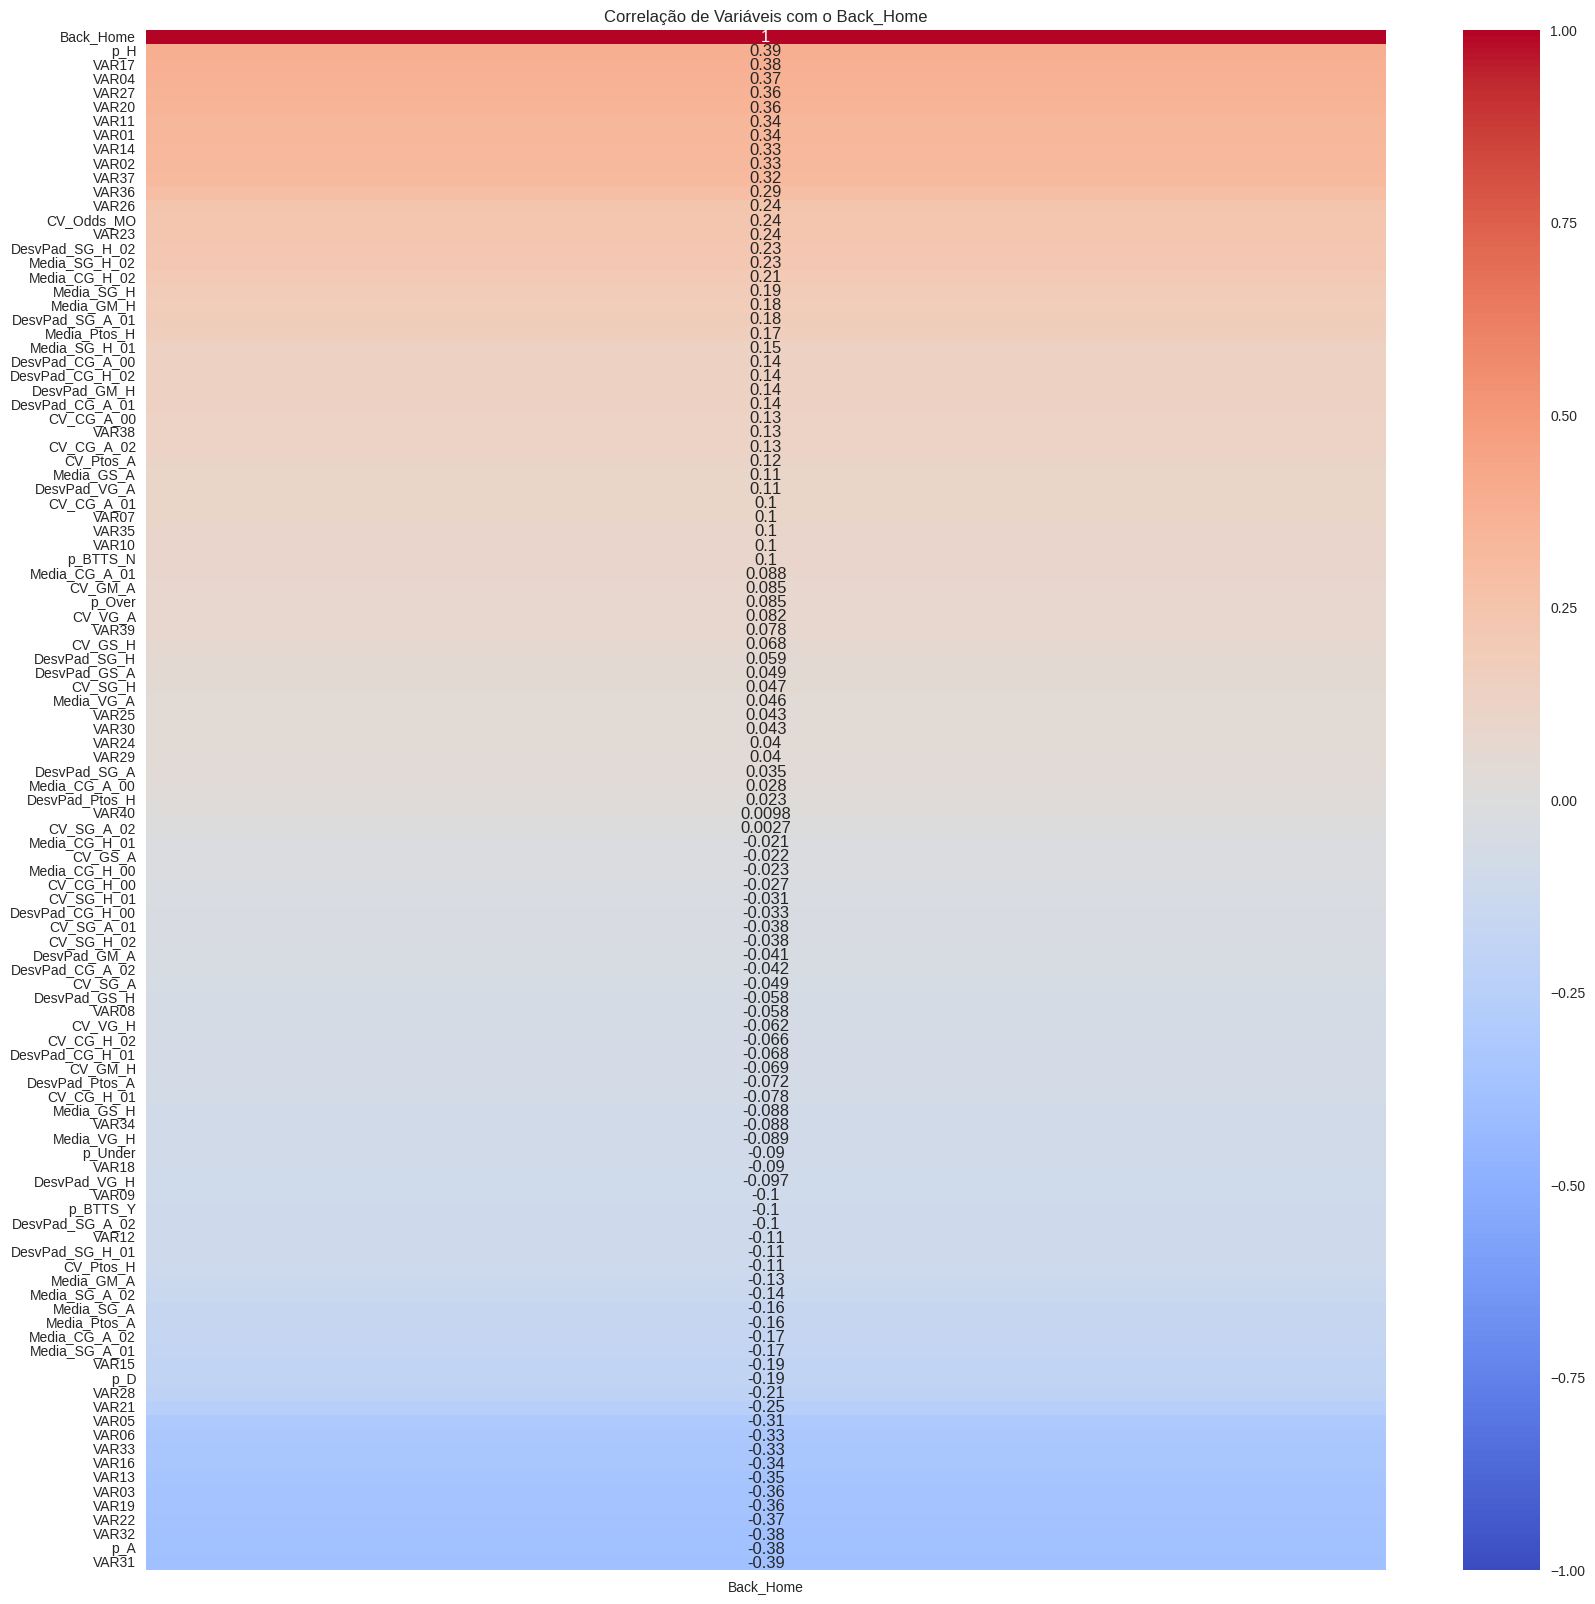

In [12]:
correlacao = df0.corr()
plt.figure(figsize= (20,20))

sns.heatmap(correlacao[[label]].sort_values(by=label, ascending=False),
            annot=True,
            cmap='coolwarm',
            vmin=-1,
            vmax=1)
plt.title(f"Correlação de Variáveis com o {label}")
plt.show()

In [13]:
df_variaveis = correlacao[['Back_Home']].sort_values(by='Back_Home', ascending=False)
flt = df_variaveis.Back_Home >= 0.10
variaveis = df_variaveis[flt]
features = variaveis.index.tolist()

if label in features:
    features.remove(label)

display(features)

['p_H',
 'VAR17',
 'VAR04',
 'VAR27',
 'VAR20',
 'VAR11',
 'VAR01',
 'VAR14',
 'VAR02',
 'VAR37',
 'VAR36',
 'VAR26',
 'CV_Odds_MO',
 'VAR23',
 'DesvPad_SG_H_02',
 'Media_SG_H_02',
 'Media_CG_H_02',
 'Media_SG_H',
 'Media_GM_H',
 'DesvPad_SG_A_01',
 'Media_Ptos_H',
 'Media_SG_H_01',
 'DesvPad_CG_A_00',
 'DesvPad_CG_H_02',
 'DesvPad_GM_H',
 'DesvPad_CG_A_01',
 'CV_CG_A_00',
 'VAR38',
 'CV_CG_A_02',
 'CV_Ptos_A',
 'Media_GS_A',
 'DesvPad_VG_A',
 'CV_CG_A_01',
 'VAR07',
 'VAR35',
 'VAR10',
 'p_BTTS_N']

In [14]:
base = df.copy()

stake = 1
green = stake * (base.Odd_H - 1)
red = -stake

base.loc[(base['Back_Home'] == 1), 'Profit'] = green
base.loc[(base['Back_Home'] == 0), 'Profit'] = red

treino = base[base['Date'].dt.year <= 2022]
treino = drop_reset_index(treino)

teste = base[base['Date'].dt.year >= 2023]
teste = drop_reset_index(teste)

In [15]:
Back_Home = setup(data = treino[features], target = treino[label], session_id=123, verbose = False)

In [16]:
df_models = models()
modelos = df_models.index.tolist()
modelos

['lr',
 'knn',
 'nb',
 'dt',
 'svm',
 'rbfsvm',
 'gpc',
 'mlp',
 'ridge',
 'rf',
 'qda',
 'ada',
 'gbc',
 'lda',
 'et',
 'xgboost',
 'lightgbm',
 'dummy']

In [17]:
lista = []

for i in modelos:

    modelo = create_model(i, verbose=False)
    df0 = predict_model(modelo, teste, verbose=False)

    try:
        filtro = df0.prediction_label == 1
        df0 = df0[filtro]
        df0 = drop_reset_index(df0)

        df0['Profit_acu'] = df0.Profit.cumsum()
        n_apostas = df0.shape[0]
        profit = round(df0.Profit_acu.tail(1).item(), 2)
        ROI = round((df0.Profit_acu.tail(1) / n_apostas * 100).item(), 2)
        drawdown = df0['Profit_acu'] - df0['Profit_acu'].cummax()
        drawdown_maximo = round(drawdown.min(), 2)
        winrate_medio = round((df0['Profit'] > 0).mean() * 100, 2)
        desvio_padrao = round(df0['Profit'].std(), 2)

        metodos = {}

        metodos["Método"] = i
        metodos["Profit"] = profit
        metodos["Nº de Jogos"] = n_apostas
        metodos["ROI"] = ROI
        metodos["DrawDown"] = drawdown_maximo
        metodos["WinRate"] = winrate_medio
        metodos["DesvPad"] = desvio_padrao

        lista.append(metodos)
        print(f'Modelo: {i}, Profit: {profit}')

    except:
        print(f'Erro no Modelo {modelo}')

Modelo: lr, Profit: 0.9
Modelo: knn, Profit: 16.57
Modelo: nb, Profit: 7.85
Modelo: dt, Profit: -3.46
Modelo: svm, Profit: 1.41
Modelo: rbfsvm, Profit: 5.98
Modelo: gpc, Profit: -10.59
Modelo: mlp, Profit: 2.17
Modelo: ridge, Profit: -2.42
Modelo: rf, Profit: -2.88
Modelo: qda, Profit: -7.34
Modelo: ada, Profit: 0.97
Modelo: gbc, Profit: 1.91
Modelo: lda, Profit: -1.02
Modelo: et, Profit: 0.35
Modelo: xgboost, Profit: 12.02
Modelo: lightgbm, Profit: 7.11
Erro no Modelo DummyClassifier(constant=None, random_state=123, strategy='prior')


In [18]:
df_modelos = pd.DataFrame(lista)
df_modelos = df_modelos.sort_values(by='Profit',ascending=False)
flt = (df_modelos['Nº de Jogos'] >= 50) & (df_modelos['Profit'] >= 5)
df_modelos = df_modelos[flt]
df_modelos = drop_reset_index(df_modelos)
display(df_modelos.head())

,Método,Profit,Nº de Jogos,ROI,DrawDown,WinRate,DesvPad
1,knn,16.57,171,9.69,-8.57,66.08,0.87
2,xgboost,12.02,180,6.68,-6.91,63.33,0.88
3,nb,7.85,179,4.39,-10.37,67.04,0.77
4,lightgbm,7.11,179,3.97,-7.11,63.13,0.86
5,rbfsvm,5.98,148,4.04,-10.95,64.86,0.82


In [19]:
try:
    best_method = df_modelos['Método'][1]
    print(f'Melhor Método: {best_method}')
    Back_Home_PyCaret = create_model(best_method, verbose=False)

    jogos_do_dia = read_jogos(dia)
    jogos_do_dia = jogos_do_dia[['League','Date','Time','Home','Away','Odd_H','Odd_D','Odd_A','Odd_Over25','Odd_Under25','Odd_BTTS_Yes','Odd_BTTS_No']]
    Jogos_do_Dia = jogos_do_dia[jogos_do_dia['League'].isin(league) == True]
    Jogos_do_Dia = drop_reset_index(Jogos_do_Dia)
    display(Jogos_do_Dia)
except:
    pass

Melhor Método: knn


,League,Date,Time,Home,Away,Odd_H,Odd_D,Odd_A,Odd_Over25,Odd_Under25,Odd_BTTS_Yes,Odd_BTTS_No
1,SPAIN - LALIGA,13/04/2024,09:00,Atl. Madrid,Girona,1.91,3.6,3.80,1.62,2.25,1.57,2.25
2,SPAIN - LALIGA,13/04/2024,11:15,Rayo Vallecano,Getafe,2.20,3.0,3.70,2.60,1.48,2.10,1.67
3,SPAIN - LALIGA,13/04/2024,13:30,Mallorca,Real Madrid,5.00,3.6,1.75,2.08,1.73,1.95,1.80
4,SPAIN - LALIGA,13/04/2024,16:00,Cadiz CF,Barcelona,4.33,3.6,1.83,2.01,1.89,1.80,1.95


In [20]:
# Probabilidades
Jogos_do_Dia['p_H'] = 1 / Jogos_do_Dia['Odd_H']
Jogos_do_Dia['p_D'] = 1 / Jogos_do_Dia['Odd_D']
Jogos_do_Dia['p_A'] = 1 / Jogos_do_Dia['Odd_A']
Jogos_do_Dia['p_Over'] = 1 / Jogos_do_Dia['Odd_Over25']
Jogos_do_Dia['p_Under'] = 1 / Jogos_do_Dia['Odd_Under25']
Jogos_do_Dia['p_BTTS_Y'] = 1 / Jogos_do_Dia['Odd_BTTS_Yes']
Jogos_do_Dia['p_BTTS_N'] = 1 / Jogos_do_Dia['Odd_BTTS_No']

# CV das Probabilidades
desvio_padrao = Jogos_do_Dia[['p_H','p_D','p_A']].std(axis=1)
media = Jogos_do_Dia[['p_H','p_D','p_A']].mean(axis=1)
cv_odds = desvio_padrao / media
Jogos_do_Dia['CV_Odds_MO'] = cv_odds

# Razões entre as Probabilidades
Jogos_do_Dia['VAR01'] = Jogos_do_Dia['p_H'] / Jogos_do_Dia['p_D']
Jogos_do_Dia['VAR02'] = Jogos_do_Dia['p_H'] / Jogos_do_Dia['p_A']
Jogos_do_Dia['VAR03'] = Jogos_do_Dia['p_D'] / Jogos_do_Dia['p_H']
Jogos_do_Dia['VAR04'] = Jogos_do_Dia['p_D'] / Jogos_do_Dia['p_A']
Jogos_do_Dia['VAR05'] = Jogos_do_Dia['p_A'] / Jogos_do_Dia['p_H']
Jogos_do_Dia['VAR06'] = Jogos_do_Dia['p_A'] / Jogos_do_Dia['p_D']
Jogos_do_Dia['VAR07'] = Jogos_do_Dia['p_Over'] / Jogos_do_Dia['p_Under']
Jogos_do_Dia['VAR08'] = Jogos_do_Dia['p_Under'] / Jogos_do_Dia['p_Over']
Jogos_do_Dia['VAR09'] = Jogos_do_Dia['p_BTTS_Y'] / Jogos_do_Dia['p_BTTS_N']
Jogos_do_Dia['VAR10'] = Jogos_do_Dia['p_BTTS_N'] / Jogos_do_Dia['p_BTTS_Y']
Jogos_do_Dia['VAR11'] = Jogos_do_Dia['p_H'] / Jogos_do_Dia['p_Over']
Jogos_do_Dia['VAR12'] = Jogos_do_Dia['p_D'] / Jogos_do_Dia['p_Over']
Jogos_do_Dia['VAR13'] = Jogos_do_Dia['p_A'] / Jogos_do_Dia['p_Over']
Jogos_do_Dia['VAR14'] = Jogos_do_Dia['p_H'] / Jogos_do_Dia['p_Under']
Jogos_do_Dia['VAR15'] = Jogos_do_Dia['p_D'] / Jogos_do_Dia['p_Under']
Jogos_do_Dia['VAR16'] = Jogos_do_Dia['p_A'] / Jogos_do_Dia['p_Under']
Jogos_do_Dia['VAR17'] = Jogos_do_Dia['p_H'] / Jogos_do_Dia['p_BTTS_Y']
Jogos_do_Dia['VAR18'] = Jogos_do_Dia['p_D'] / Jogos_do_Dia['p_BTTS_Y']
Jogos_do_Dia['VAR19'] = Jogos_do_Dia['p_A'] / Jogos_do_Dia['p_BTTS_Y']
Jogos_do_Dia['VAR20'] = Jogos_do_Dia['p_H'] / Jogos_do_Dia['p_BTTS_N']
Jogos_do_Dia['VAR21'] = Jogos_do_Dia['p_D'] / Jogos_do_Dia['p_BTTS_N']
Jogos_do_Dia['VAR22'] = Jogos_do_Dia['p_A'] / Jogos_do_Dia['p_BTTS_N']

# Coeficientes de Variações das Odds
Jogos_do_Dia['VAR23'] = Jogos_do_Dia[['Odd_H','Odd_D','Odd_A']].std(ddof=0, axis=1) / Jogos_do_Dia[['Odd_H','Odd_D','Odd_A']].mean(axis=1)
Jogos_do_Dia['VAR24'] = Jogos_do_Dia[['Odd_Over25', 'Odd_Under25']].std(ddof=0, axis=1) / Jogos_do_Dia[['Odd_Over25', 'Odd_Under25']].mean(axis=1)
Jogos_do_Dia['VAR25'] = Jogos_do_Dia[['Odd_BTTS_Yes', 'Odd_BTTS_No']].std(ddof=0, axis=1) / Jogos_do_Dia[['Odd_BTTS_Yes', 'Odd_BTTS_No']].mean(axis=1)

# Distância Absoluta entre as Probabilidades
Jogos_do_Dia['VAR26'] = np.abs(Jogos_do_Dia['p_H'] - Jogos_do_Dia['p_A'])
Jogos_do_Dia['VAR27'] = np.abs(Jogos_do_Dia['p_H'] - Jogos_do_Dia['p_D'])
Jogos_do_Dia['VAR28'] = np.abs(Jogos_do_Dia['p_D'] - Jogos_do_Dia['p_A'])
Jogos_do_Dia['VAR29'] = np.abs(Jogos_do_Dia['p_Over'] - Jogos_do_Dia['p_Under'])
Jogos_do_Dia['VAR30'] = np.abs(Jogos_do_Dia['p_BTTS_Y'] - Jogos_do_Dia['p_BTTS_N'])

# Distância Angular entre as Probabilidades
Jogos_do_Dia['VAR31'] = np.degrees(np.arctan((Jogos_do_Dia['p_A'] - Jogos_do_Dia['p_H']) / 2))
Jogos_do_Dia['VAR32'] = np.degrees(np.arctan((Jogos_do_Dia['p_D'] - Jogos_do_Dia['p_H']) / 2))
Jogos_do_Dia['VAR33'] = np.degrees(np.arctan((Jogos_do_Dia['p_A'] - Jogos_do_Dia['p_D']) / 2))
Jogos_do_Dia['VAR34'] = np.degrees(np.arctan((Jogos_do_Dia['p_Under'] - Jogos_do_Dia['p_Over']) / 2))
Jogos_do_Dia['VAR35'] = np.degrees(np.arctan((Jogos_do_Dia['p_BTTS_N'] - Jogos_do_Dia['p_BTTS_Y']) / 2))

# Distância Relativa entre as Probabilidades
Jogos_do_Dia['VAR36'] = np.abs((Jogos_do_Dia['p_H'] - Jogos_do_Dia['p_A'])) / Jogos_do_Dia['p_A']
Jogos_do_Dia['VAR37'] = np.abs((Jogos_do_Dia['p_H'] - Jogos_do_Dia['p_D'])) / Jogos_do_Dia['p_D']
Jogos_do_Dia['VAR38'] = np.abs((Jogos_do_Dia['p_D'] - Jogos_do_Dia['p_A'])) / Jogos_do_Dia['p_A']
Jogos_do_Dia['VAR39'] = np.abs((Jogos_do_Dia['p_Over'] - Jogos_do_Dia['p_Under'])) / Jogos_do_Dia['p_Under']
Jogos_do_Dia['VAR40'] = np.abs((Jogos_do_Dia['p_BTTS_Y'] - Jogos_do_Dia['p_BTTS_N'])) / Jogos_do_Dia['p_BTTS_N']
Jogos_do_Dia

,League,Date,Time,Home,Away,Odd_H,Odd_D,Odd_A,Odd_Over25,Odd_Under25,...,VAR31,VAR32,VAR33,VAR34,VAR35,VAR36,VAR37,VAR38,VAR39,VAR40
1,SPAIN - LALIGA,13/04/2024,09:00,Atl. Madrid,Girona,1.91,3.6,3.80,1.62,2.25,...,-7.418246,-7.006020,-0.418821,-4.939216,-5.497733,0.989529,0.884817,0.055556,0.388889,0.433121
2,SPAIN - LALIGA,13/04/2024,11:15,Rayo Vallecano,Getafe,2.20,3.0,3.70,2.60,1.48,...,-5.264232,-3.468229,-1.806025,8.280135,3.508182,0.681818,0.363636,0.233333,0.430769,0.204762
3,SPAIN - LALIGA,13/04/2024,13:30,Mallorca,Real Madrid,5.00,3.6,1.75,2.08,1.73,...,10.520784,2.227047,8.352794,2.784256,1.224083,0.650000,0.280000,0.513889,0.168269,0.076923
4,SPAIN - LALIGA,13/04/2024,16:00,Cadiz CF,Barcelona,4.33,3.6,1.83,2.01,1.89,...,8.964569,1.341361,7.651033,0.904857,-1.224083,0.577367,0.168591,0.491667,0.059701,0.083333


In [21]:
base_H = base[['Home','Media_Ptos_H','DesvPad_Ptos_H','CV_Ptos_H',
'Media_GM_H','DesvPad_GM_H','CV_GM_H',
'Media_GS_H','DesvPad_GS_H','CV_GS_H',
'Media_SG_H','DesvPad_SG_H','CV_SG_H',
'Media_SG_H_01','DesvPad_SG_H_01','CV_SG_H_01',
'Media_SG_H_02','DesvPad_SG_H_02','CV_SG_H_02',
'Media_VG_H','DesvPad_VG_H','CV_VG_H',
'Media_CG_H_00','DesvPad_CG_H_00','CV_CG_H_00',
'Media_CG_H_01','DesvPad_CG_H_01','CV_CG_H_01',
'Media_CG_H_02','DesvPad_CG_H_02','CV_CG_H_02']]

base_A = base[['Away','Media_Ptos_A','DesvPad_Ptos_A','CV_Ptos_A',
'Media_GM_A','DesvPad_GM_A','CV_GM_A',
'Media_GS_A','DesvPad_GS_A','CV_GS_A',
'Media_SG_A','DesvPad_SG_A','CV_SG_A',
'Media_SG_A_01','DesvPad_SG_A_01','CV_SG_A_01',
'Media_SG_A_02','DesvPad_SG_A_02','CV_SG_A_02',
'Media_VG_A','DesvPad_VG_A','CV_VG_A',
'Media_CG_A_00','DesvPad_CG_A_00','CV_CG_A_00',
'Media_CG_A_01','DesvPad_CG_A_01','CV_CG_A_01',
'Media_CG_A_02','DesvPad_CG_A_02','CV_CG_A_02']]

In [22]:
ultima_base_H = base_H.groupby('Home').last().reset_index()
ultima_base_A = base_A.groupby('Away').last().reset_index()

df = pd.merge(Jogos_do_Dia, ultima_base_H, how='left', left_on='Home', right_on='Home')
df = pd.merge(df, ultima_base_A, how='left', left_on='Away', right_on='Away')

df = drop_reset_index(df)

df1 = predict_model(Back_Home_PyCaret, data=df)
filtro = df1.prediction_label == 1
Entradas = df1[filtro]
Entradas = Entradas[['League','Date','Time','Home','Away','Odd_H','Odd_D','Odd_A']]
Entradas = drop_reset_index(Entradas)
display(Entradas)

,League,Date,Time,Home,Away,Odd_H,Odd_D,Odd_A
1,SPAIN - LALIGA,13/04/2024,11:15,Rayo Vallecano,Getafe,2.2,3.0,3.7


### Resultados

In [23]:
flt = base_orig.Date == str(dia)
base_today = base_orig[flt]
base_today = base_today[['League','Round','Home','Away','Goals_H','Goals_A','Goals_Minutes_Home','Goals_Minutes_Away']]
base_today = drop_reset_index(base_today)

Entradas = pd.merge(Entradas, base_today, on=['League','Home', 'Away'])
Entradas = drop_reset_index(Entradas)
Entradas['Profit'] = np.where((Entradas['Goals_H'] >  Entradas['Goals_A']), Entradas['Odd_H']-1, -1)
Entradas['Profit_Acu'] = Entradas['Profit'].cumsum()
Entradas

,League,Date,Time,Home,Away,Odd_H,Odd_D,Odd_A,Round,Goals_H,Goals_A,Goals_Minutes_Home,Goals_Minutes_Away,Profit,Profit_Acu
1,SPAIN - LALIGA,13/04/2024,11:15,Rayo Vallecano,Getafe,2.2,3.0,3.7,ROUND 31,0,0,[],[],-1.0,-1.0
